Quantum Walk with Classical Parrondo Game
-------------------------------------------------------------------------------------------------------------------------

In [1]:
from qiskit import *
import numpy as np
#Game A Probabilities
p_lose=0.505
angle=2 * np.arccos(np.sqrt(p_lose))
#Game B Probabilities
p_lose_mod3=0.905 
angle_mod3=2 * np.arccos(np.sqrt(p_lose_mod3))
p_lose_not_mod3=0.255
angle_not_mod3=2 * np.arccos(np.sqrt(p_lose_not_mod3))

In [2]:
#adder matrix operator
payoff_register_qubits=5
size = 2**payoff_register_qubits
matrix_a = np.zeros((size, size), dtype=int)
for i in range(size):
    for j in range(size):
        if j == (i - 1) % size:
            matrix_a[i, j] = 1
#print(matrix_a) # use if you want to see the matrix

In [3]:
# subtractor matrix operator
matrix_s = np.zeros((size, size), dtype=int)
for i in range(size):
    for j in range(size):
        # Flip the specific position to 1
        if j == (i + 1) % size:
            matrix_s[i, j] = 1

#print(matrix_s) #use if you want to see the matrix


In [4]:
from qiskit.circuit.library import UnitaryGate
#necessary declarations of the controlled_adder and controlled_subtractor gates for use in the quantum circuit construction
adder = UnitaryGate(matrix_a, label="AdderGate")
controlled_adder = adder.control(num_ctrl_qubits=1, ctrl_state='1')
subtractor = UnitaryGate(matrix_s, label="SubtractorGate")
controlled_subtractor = subtractor.control(num_ctrl_qubits=1, ctrl_state='0')

In [5]:
#The desired number of steps of the Quantum Walk. Each step consists of the application of Game A and Game B simultaneously.
steps=3
#Defining the Size of the Quantum Circuit in terms of the number of qubits in each register and the total number of qubits.
payoff_register_list=[]
for j in range(payoff_register_qubits,2*payoff_register_qubits):
    payoff_register_list.append(j)
ancilla_register_qubits=2 #do not change
circuit_number_of_qubits= 2*payoff_register_qubits + ancilla_register_qubits + steps * 1
#Declaration of the Quantum Circuit and initialization of the payoff register to the state |3>
total= QuantumCircuit(circuit_number_of_qubits, name='QECPW Circuit')
total.x(4+payoff_register_qubits) #initialization of the payoff register to the state |3>

total.barrier()

#The Construction of the Quantum Circuit for the Quantum Parrondo's Walk.
for i in range(steps):
    #compute stage
    game_select_register_qubit_index=2*payoff_register_qubits+ancilla_register_qubits+i
    #Setting Each Qubit of the Game Select Register to the Superposition State |+> to create an equal superposition of all possible game sequences.
    total.h(game_select_register_qubit_index)
    #Game A probability application to the second ancilla qubit of the Game Apply Register
    second_ancilla_qubit_index=2*payoff_register_qubits+ancilla_register_qubits-1
    total.cry(angle,game_select_register_qubit_index,second_ancilla_qubit_index,ctrl_state='0') 
    
    #Check if the payoff register state is mod3 or not and store the result in the first ancilla qubit of the Game Apply Register (qubit=0 if mod3, qubit=1 if NOT mod3)
    first_ancilla_qubit_index=2*payoff_register_qubits

    control_qubits = list(reversed(range(payoff_register_qubits, 2*payoff_register_qubits)))
    total.x(first_ancilla_qubit_index) # Αντιστρέφουμε το q5 ώστε το '0' να γίνει '1' για να "νιώσει" η πύλη το control
    mod3_states = [f"{i:0{payoff_register_qubits}b}" for i in range(0, 2**payoff_register_qubits, 3)]
    for state in mod3_states:
        total.mcx(control_qubits, first_ancilla_qubit_index, ctrl_state=state)
    

    #Calculate the corresponding Game B probabilities for the mod3 case 
    total.x(first_ancilla_qubit_index) # Αντιστρέφουμε το q5 ώστε το '0' να γίνει '1' για να "νιώσει" η πύλη το control
    total.mcry(angle_mod3, [first_ancilla_qubit_index,game_select_register_qubit_index],second_ancilla_qubit_index)
    total.x(first_ancilla_qubit_index) # Επαναφέρουμε το q5 στην αρχική του κατάσταση (Uncompute)

    #Calculate the corresponding Game B probabilities for the not mod3 case 
    total.mcry(angle_not_mod3, [first_ancilla_qubit_index,game_select_register_qubit_index],second_ancilla_qubit_index)
    qubit_indices = [second_ancilla_qubit_index] + payoff_register_list
    total.append(controlled_adder, qubit_indices)
    total.append(controlled_subtractor, qubit_indices)
###################################################################################################
##copy stage
    total.barrier()
    for j in range(payoff_register_qubits+1):
        if(j==0):
            continue
        total.cx(2*payoff_register_qubits-j, first_ancilla_qubit_index-j-payoff_register_qubits)
    total.barrier()

###################################################################################################
##uncompute stage

    # 1. Inverse of the Subtractor and Adder
    # (Applied in reverse order of the compute stage, assuming they are Qiskit Gate objects)
    total.append(controlled_subtractor.inverse(), qubit_indices)
    total.append(controlled_adder.inverse(), qubit_indices)

    # 2. Inverse of the Game B probabilities for the not mod3 case (negative angle)
    total.mcry(-angle_not_mod3, [first_ancilla_qubit_index, game_select_register_qubit_index], second_ancilla_qubit_index)

    # 3. Inverse of the Game B probabilities for the mod3 case
    total.x(first_ancilla_qubit_index) 
    total.mcry(-angle_mod3, [first_ancilla_qubit_index, game_select_register_qubit_index], second_ancilla_qubit_index)
    total.x(first_ancilla_qubit_index) 

    # 4. Inverse of the mod3 check (reversed loop for the exact reverse order)
    for state in reversed(mod3_states):
        total.mcx(control_qubits, first_ancilla_qubit_index, ctrl_state=state)
    total.x(first_ancilla_qubit_index) 

    # 5. Inverse of Game A probability application
    total.cry(-angle, game_select_register_qubit_index, second_ancilla_qubit_index, ctrl_state='0')
    total.barrier()
    if (i==0):
        total.x(4+payoff_register_qubits) # Reset the payoff register to the state |3> for the next step
        total.barrier()
    
    for j in range(payoff_register_qubits+1):
        if(j==0):
             continue
        total.cx(first_ancilla_qubit_index-j-payoff_register_qubits,2*payoff_register_qubits-j )
    total.barrier()
    total.barrier()

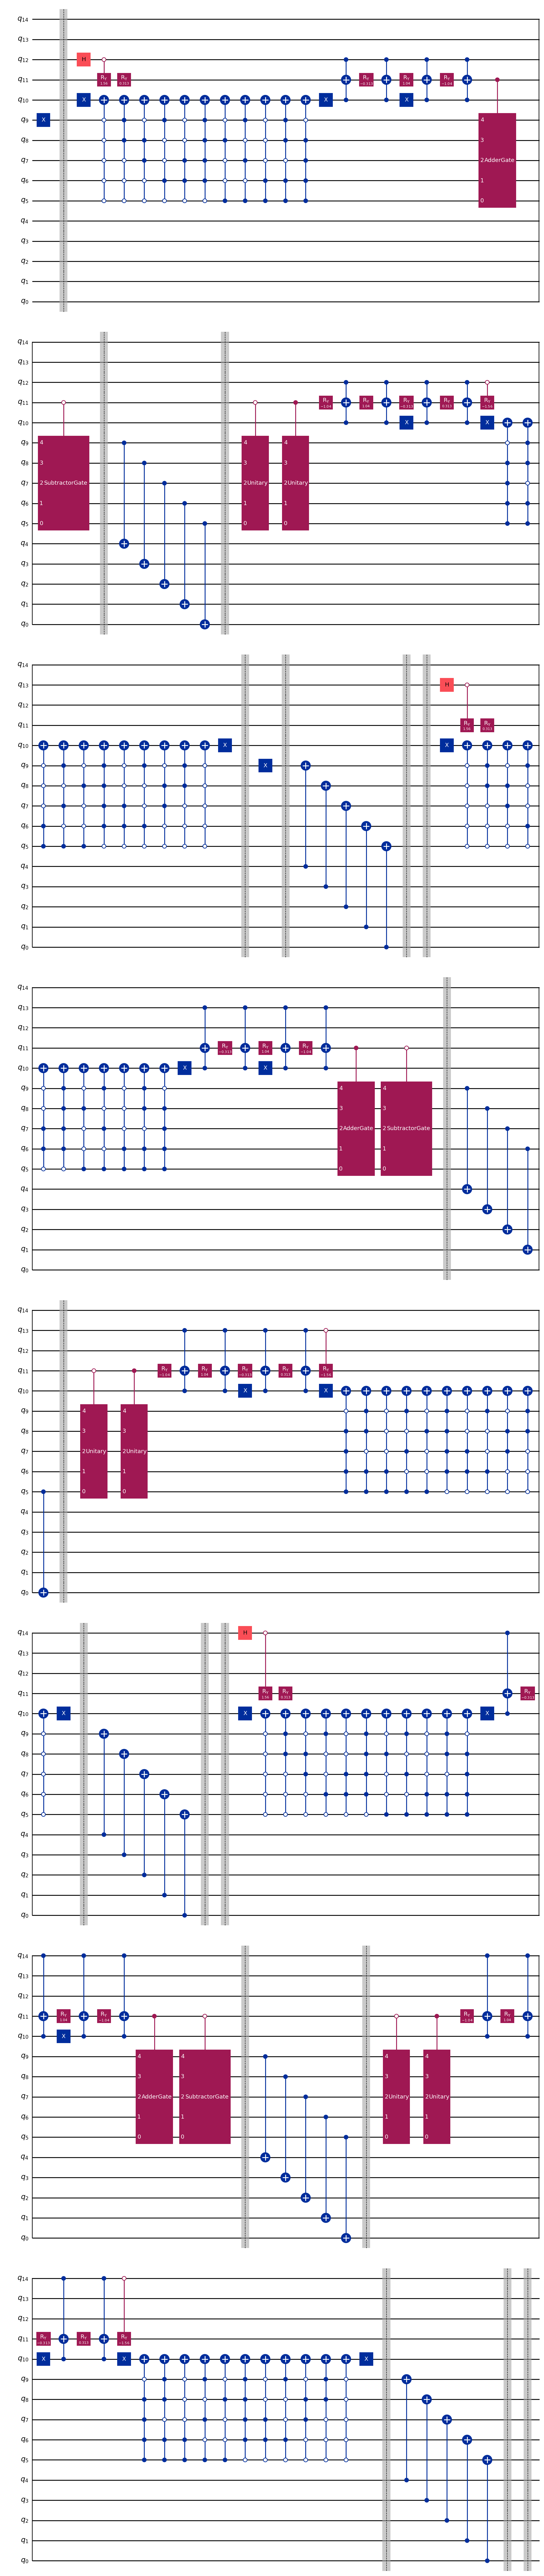

In [6]:
total.draw('mpl',reverse_bits=True)

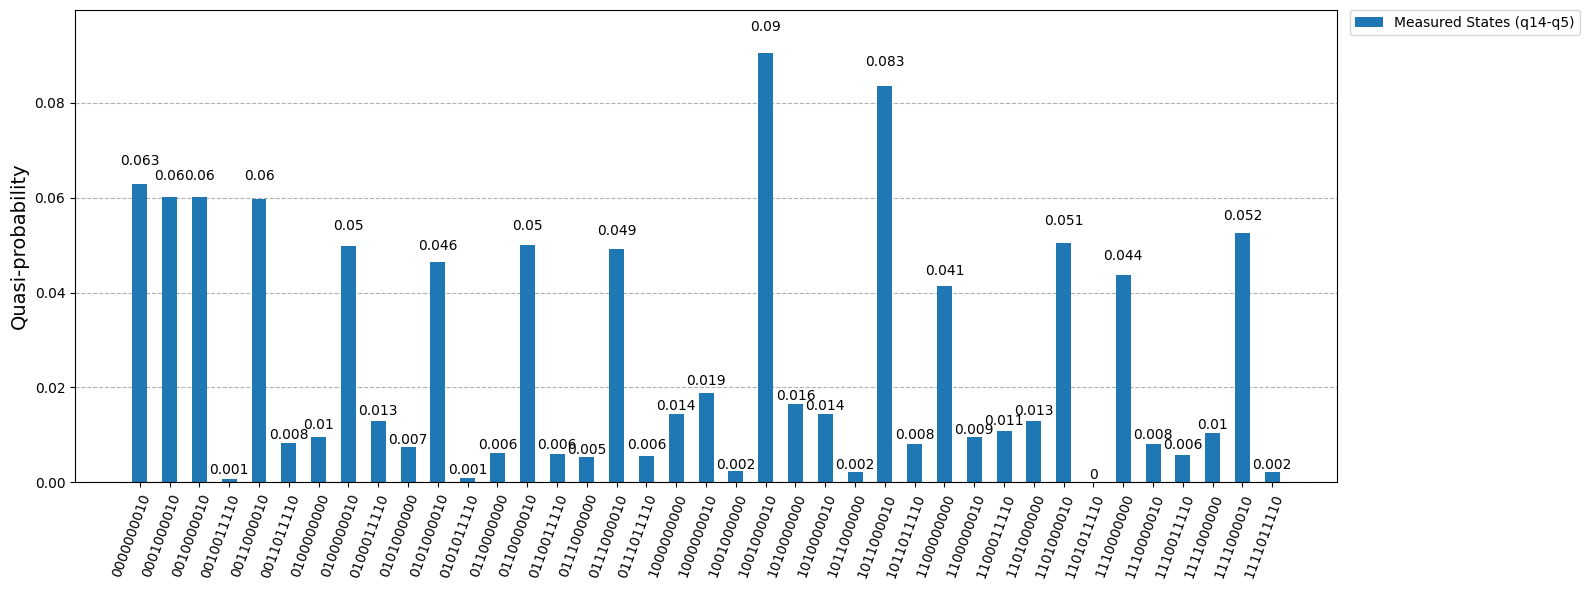

In [7]:
from collections import defaultdict
from qiskit import transpile
from qiskit.visualization import plot_distribution
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as Sampler

total.measure_all()

# 1. Setup and Transpile
backend = AerSimulator()
sampler = Sampler(options={"backend_options": {"max_parallel_threads": 10}})
transpiled_circuit = transpile(total, backend=backend, optimization_level=3)

# 2. Run the simulation
shots = 2**15
job = sampler.run([(transpiled_circuit,)], shots=shots)
result = job.result()
pub_result = result[0]

# 3. Extract and marginalize counts
# Raw bitstrings are 15 characters: [q14, q13, ..., q5, q4, q3, q2, q1, q0]
raw_counts = pub_result.data.meas.get_counts()

trimmed_counts = defaultdict(int)
for bitstring, count in raw_counts.items():
    # Keep the 10 MSB (q14 to q5) by slicing off the 5 LSB (q4 to q0)
    trimmed_key = bitstring[:-5]
    trimmed_counts[trimmed_key] += count

trimmed_counts = dict(trimmed_counts)

# 4. Plot the 10-qubit outcomes (q14 to q5)
plot_distribution(
    trimmed_counts,
    legend=['Measured States (q14-q5)'],
    figsize=(16, 6)
)